# Guardian 텍스트 전처리 · 검토용
**Primary: broad / Strict robustness: stock-market tag · Weekly**

원자료 5,265건을 한 번씩 보존하고 `text_raw`, `text_sentiment`, `text_clean`을 별도로 만들었다.
이 노트북은 기본적으로 저장 결과만 읽는다. **VADER 점수·WSI·FGI·시차·수익률은 계산하지 않는다.**
추가 불용어와 표제어화는 미적용 상태이다. 아래 결과를 보고 채택 여부를 결정한다.

In [1]:
from pathlib import Path
import runpy,json
BASE=Path.cwd().resolve()
if not (BASE/"guardian_text_preprocess.py").exists():
    BASE=BASE/"midterm paper"
pipeline=runpy.run_path(str(BASE/"guardian_text_preprocess.py"))
import pandas as pd
from IPython.display import display,Markdown,Image
RESULTS=BASE/"results/guardian_text_preprocessing"
pd.set_option("display.max_colwidth",110)
diagnostics=json.loads((RESULTS/"preprocessing_diagnostics.json").read_text(encoding="utf-8"))
STRATEGY="broad_business_control"  # anchors_stock_market_tag로 변경 가능
TOP_N=20  # 파일에는 각 전략 상위 100개를 저장했다.
print("Physical articles:",diagnostics["physical_article_records"])

Physical articles: 5265


## 1. 규칙과 중복 진단
`headline`을 우선 사용하며 `web_title`도 원본 그대로 보존한다. 표시 텍스트의 정확한 중복만 결합 시 한 번 제외한다.
near-duplicate 후보는 표시만 한다. HTML 제거는 감성용/빈도용 새 열에서만 수행한다.

In [2]:
display(pd.DataFrame(diagnostics["strategy_token_counts"]))
print({name:diagnostics[name] for name in ["headline_differs_from_web_title","headline_description_exact_raw","headline_description_exact_visible","headline_description_near_duplicate","articles_with_html","articles_with_html_entities","articles_with_urls","empty_text_clean"]})
display(pd.read_csv(RESULTS/"headline_description_duplicates.csv").head(20))
inspection=pd.read_csv(RESULTS/"preprocessing_inspection_sample.csv",keep_default_na=False)
display(inspection[["guardian_id","headline_for_text","description","text_raw","text_sentiment","text_clean"]].head(8))

,query_strategy,articles,raw_tokens,sentiment_visible_tokens,before_stopwords_tokens,clean_tokens,tokens_removed_raw_to_clean_pct,clean_vocabulary
0,broad_business_control,5054,155246,154979,154614,112409,27.592981,12556
1,anchors_stock_market_tag,2512,79634,79511,79216,57888,27.307431,7338


{'headline_differs_from_web_title': 333, 'headline_description_exact_raw': 0, 'headline_description_exact_visible': 0, 'headline_description_near_duplicate': 0, 'articles_with_html': 135, 'articles_with_html_entities': 88, 'articles_with_urls': 0, 'empty_text_clean': 0}


,guardian_id,year,headline,description,exact_raw,exact_visible,near_duplicate,similarity


,guardian_id,headline_for_text,description,text_raw,text_sentiment,text_clean
0,business/2017/jan/03/stock-markets-share-tips-guardian-2017-political-certainty-earners,Stock markets: the Guardian's share tips for 2017,"After the political shocks of 2016 resulted in a surprise price boost, our team dust off their crystal bal...",Stock markets: the Guardian's share tips for 2017\nAfter the political shocks of 2016 resulted in a surpri...,Stock markets: the Guardian's share tips for 2017 After the political shocks of 2016 resulted in a surpris...,stock markets guardian's share tips 2017 political shocks 2016 resulted surprise price boost team dust off...
1,business/blog/live/2017/jan/03/markets-wait-for-uk-manufacturing-data-ftse-100-business-live,UK manufacturing PMI rises to two-year high as FTSE 100 hits fresh record – as it happened,Sterling rises to two-week high after strong manufacturing survey,UK manufacturing PMI rises to two-year high as FTSE 100 hits fresh record – as it happened\nSterling rises...,UK manufacturing PMI rises to two-year high as FTSE 100 hits fresh record – as it happened Sterling rises ...,uk manufacturing pmi rises two-year high ftse_100 hits fresh record happened sterling rises two-week high ...
2,business/2018/jan/02/the-guardians-share-tips-for-2018,The Guardian's share tips for 2018,Global stock markets hitting record high bodes well for investors as we present our top picks for the year...,The Guardian's share tips for 2018\nGlobal stock markets hitting record high bodes well for investors as w...,The Guardian's share tips for 2018 Global stock markets hitting record high bodes well for investors as we...,guardian's share tips 2018 global stock markets hitting record high bodes well investors present top picks...
3,business/2018/jan/02/marks-spencer-sells-hong-kong-macau-al-futtaim,Marks & Spencer sells Hong Kong stores as it retreats from overseas markets,Sale of 27 stores in Hong Kong and Macau to Al-Futtaim comes as it closes UK outlets under turnaround plan,Marks & Spencer sells Hong Kong stores as it retreats from overseas markets\nSale of 27 stores in Hong Kon...,Marks & Spencer sells Hong Kong stores as it retreats from overseas markets Sale of 27 stores in Hong Kong...,marks spencer sells hong kong stores retreats overseas markets sale 27 stores hong kong macau al-futtaim c...
4,business/2019/jan/01/the-guardians-share-tips-for-2019,The Guardian's share tips for 2019,"Brexit and trade wars still spooking the markets – plus, how we did with last year’s tips","The Guardian's share tips for 2019\nBrexit and trade wars still spooking the markets – plus, how we did wi...","The Guardian's share tips for 2019 Brexit and trade wars still spooking the markets – plus, how we did wit...",guardian's share tips 2019 brexit trade wars still spooking markets plus last year's tips
5,business/2019/jan/02/factory-output-jumps-as-stockpiling-increases-amid-brexit-fears-uk,Factory output jumps as stockpiling increases amid Brexit fears,UK buildup of finished goods rises in December at second-fastest rate since 1992,Factory output jumps as stockpiling increases amid Brexit fears\nUK buildup of finished goods rises in Dec...,Factory output jumps as stockpiling increases amid Brexit fears UK buildup of finished goods rises in Dece...,factory output jumps stockpiling increases amid brexit fears uk buildup finished goods rises december seco...
6,business/2020/jan/01/us-election-brexit-and-china-to-sway-the-markets-in-2020,"US election, Brexit and China to sway the markets in 2020",Investors expect a strong year but the presidential race and trade wars could spring nasty surprises<br>,"US election, Brexit and China to sway the markets in 2020\nInvestors expect a strong year but the presiden...","US election, Brexit and China to sway the markets in 2020 Investors expect a strong year but the president...",us election brexit china sway markets 2020 investors expect strong year presidential race trade wars could...
7

## 2. Raw / clean 상위 토큰
raw는 HTML·URL 제거 전, 원래 대소문자의 토큰이다. clean은 별도 빈도 입력이며 시장 표기 정규화와 기본 불용어 제거를 포함한다.
기사 수나 토큰 수가 다른 두 전략의 빈도를 단순 합쳐 해석하지 않는다.

In [3]:
for filename in ["top_100_raw_tokens.csv","top_100_cleaned_tokens.csv","common_bigrams.csv"]:
    table=pd.read_csv(RESULTS/filename)
    display(Markdown(f"**{filename} · {STRATEGY}**"))
    display(table.loc[table.query_strategy.eq(STRATEGY)].head(TOP_N))

**top_100_raw_tokens.csv · broad_business_control**

,query_strategy,rank,term,count,document_count
0,broad_business_control,1,as,4760,3061
1,broad_business_control,2,to,3908,2638
2,broad_business_control,3,of,3683,2802
3,broad_business_control,4,and,3645,2808
4,broad_business_control,5,the,3452,2350
5,broad_business_control,6,in,2613,2022
6,broad_business_control,7,it,2507,2405
7,broad_business_control,8,happened,2101,2101
8,broad_business_control,9,UK,1686,1379
9,broad_business_control,10,US,1612,1353


**top_100_cleaned_tokens.csv · broad_business_control**

,query_strategy,rank,term,count,document_count
0,broad_business_control,1,happened,2101,2101
1,broad_business_control,2,uk,1686,1379
2,broad_business_control,3,us,1633,1369
3,broad_business_control,4,financial,1098,1077
4,broad_business_control,5,economic,1083,1051
5,broad_business_control,6,markets,932,843
6,broad_business_control,7,news,915,909
7,broad_business_control,8,latest,859,838
8,broad_business_control,9,coverage,854,854
9,broad_business_control,10,rolling,839,839


**common_bigrams.csv · broad_business_control**

,query_strategy,rank,bigram,count,document_count
0,broad_business_control,1,financial news,845,845
1,broad_business_control,2,rolling coverage,801,801
2,broad_business_control,3,latest economic,701,701
3,broad_business_control,4,wall street,263,261
4,broad_business_control,5,interest rates,259,235
5,broad_business_control,6,stock markets,237,231
6,broad_business_control,7,stock market,220,214
7,broad_business_control,8,interest rate,166,160
8,broad_business_control,9,trade war,159,150
9,broad_business_control,10,record high,142,138


## 3. 웹 아티팩트·상용구·추가 불용어 후보
추가 불용어는 아직 적용하지 않았다. 후보의 문서 빈도·문맥을 확인한다.
amp 등 짧은 문자열은 실제 회사/약어일 수 있으므로 자동 삭제하지 않는다.

In [4]:
display(pd.read_csv(RESULTS/"artifact_token_counts.csv"))
display(pd.read_csv(RESULTS/"boilerplate_phrase_counts.csv"))
candidates=pd.read_csv(RESULTS/"candidate_custom_stopwords.csv")
display(candidates.loc[candidates.query_strategy.eq(STRATEGY)].sort_values("count",ascending=False))
display(pd.read_csv(RESULTS/"html_web_artifact_examples.csv").head(5))

,query_strategy,token,raw_count,visible_count,clean_count,note
0,broad_business_control,amp,24,2,2,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
1,broad_business_control,apos,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
2,broad_business_control,br,103,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
3,broad_business_control,com,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
4,broad_business_control,div,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
5,broad_business_control,gt,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
6,broad_business_control,href,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
7,broad_business_control,html,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
8,broad_business_control,http,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal
9,broad_business_control,https,0,0,0,diagnostic only: some strings can be legitimate names/abbreviations; no custom removal


,query_strategy,phrase,document_count,removed
0,broad_business_control,as it happened,2096,False
1,broad_business_control,live updates,0,False
2,broad_business_control,sign up,1,False
3,broad_business_control,read more,0,False
4,broad_business_control,subscribe,0,False
5,broad_business_control,the guardian,8,False
6,broad_business_control,follow the latest,0,False
7,anchors_stock_market_tag,as it happened,1609,False
8,anchors_stock_market_tag,live updates,0,False
9,anchors_stock_market_tag,sign up,1,False


,query_strategy,candidate,count,document_count,document_share,reason,applied,examples
8,broad_business_control,happened,2101,2101,0.415710,possible web/UI boilerplate; inspect context,False,"[{""guardian_id"": ""business/blog/live/2017/jan/03/markets-wait-for-uk-manufacturing-data-ftse-100-business-..."
11,broad_business_control,news,915,909,0.179858,"possible rolling-news template; may be substantive, inspect examples",False,"[{""guardian_id"": ""business/live/2017/jan/12/marks-spencer-tesco-debenhams-primark-jd-sports-flurry-christm..."
22,broad_business_control,latest,859,838,0.165809,"generic reporting/time term; may be substantive, requires review",False,"[{""guardian_id"": ""business/live/2017/feb/24/french-consumers-resilient-depsite-political-uncertainty-busin..."
10,broad_business_control,coverage,854,854,0.168975,"possible rolling-news template; may be substantive, inspect examples",False,"[{""guardian_id"": ""business/live/2017/jan/17/davos-2017-wef-chinese-president-xi-trump-scaramucci-brexit-hs..."
9,broad_business_control,rolling,839,839,0.166007,"possible rolling-news template; may be substantive, inspect examples",False,"[{""guardian_id"": ""business/live/2017/jan/17/davos-2017-wef-chinese-president-xi-trump-scaramucci-brexit-hs..."
13,broad_business_control,says,631,583,0.115354,"generic reporting/time term; may be substantive, requires review",False,"[{""guardian_id"": ""business/2017/jan/17/top-trump-adviser-says-post-brexit-trade-deal-feasible-within-a-yea..."
15,broad_business_control,new,479,460,0.091017,"generic reporting/time term; may be substantive, requires review",False,"[{""guardian_id"": ""business/live/2017/jan/06/markets-await-last-us-jobs-data-of-the-obama-era-business-live..."
16,broad_business_control,year,425,392,0.077562,"generic reporting/time term; may be substantive, requires review",False,"[{""guardian_id"": ""business/2017/jan/03/stock-markets-share-tips-guardian-2017-political-certainty-earners""..."
23,broad_business_control,business,389,371,0.073407,"generic reporting/time term; may be substantive, requires review",False,"[{""guardian_id"": ""business/2017/jan/16/top-bosses-globalisation-pwc-survey-free-trade"", ""headline"": ""Top b..."
7,broad_business_control,live,229,226,0.044717,possible web/UI boilerplate; inspect context,False,"[{""guardian_id"": ""business/live/2017/feb/15/uk-unemployment-wages-brexit-greece-janet-yellen-business-live..."


,guardian_id,year,has_html,has_entity,has_url,text_raw,text_sentiment
0,business/live/2017/jan/04/ftse-bids-for-new-record-but-next-sales-disappoint-business-live,2017,True,False,False,UK construction sector grows but Next disappoints - as it happened\nThe UK construction sector grew at a d...,UK construction sector grows but Next disappoints - as it happened The UK construction sector grew at a de...
1,business/live/2017/jan/12/marks-spencer-tesco-debenhams-primark-jd-sports-flurry-christmas-trading-busines...,2017,False,True,False,"Marks & Spencer, Tesco, Primark and JD Sports lead flurry of Christmas trading news – as it happened\nM&am...","Marks & Spencer, Tesco, Primark and JD Sports lead flurry of Christmas trading news – as it happened M&S h..."
2,commentisfree/2017/jan/27/how-society-doing-gdp-alternatives-grain-prices-inequality,2017,True,False,False,Want to know how society's doing? Forget GDP – try these alternatives\nCrude financial instruments dominat...,Want to know how society's doing? Forget GDP – try these alternatives Crude financial instruments dominate...
3,business/2017/feb/08/turnbull-calls-australia-post-after-ceos-multimillion-salary-revealed,2017,True,False,False,"Australia Post CEO’s $5.6m salary ‘too high’, says Turnbull\n‘I think it is a very big salary for that job...","Australia Post CEO’s $5.6m salary ‘too high’, says Turnbull ‘I think it is a very big salary for that job’..."
4,business/2017/mar/01/wall-street-donald-trump-corporate-tax-dow-jones-nasdaq,2017,False,True,False,"Wall Street stocks rise after Trump's corporate tax cut promises\nDow Jones, S&amp;P 500 and Nasdaq reach ...","Wall Street stocks rise after Trump's corporate tax cut promises Dow Jones, S&P 500 and Nasdaq reach fresh..."


## 4. 표제어화 비교 · 기본 텍스트에는 미적용
어휘 감소가 의미 보존을 입증하지는 않는다. noun-only WordNet의 원래 변환과 보호 규칙을 함께 검토한다.
특히 국가/시장 약어를 일반 명사·동사처럼 처리하지 않는다.

In [5]:
lemma=json.loads((RESULTS/"lemmatization_evaluation.json").read_text(encoding="utf-8"))
print(json.dumps(lemma,ensure_ascii=False,indent=2))
display(pd.read_csv(RESULTS/"lemmatization_risk_probes.csv"))
mapping=pd.read_csv(RESULTS/"lemmatization_mapping.csv")
display(mapping.loc[mapping.would_change].head(30))

{
  "scope": "all unique articles; diagnostics only",
  "baseline_vocabulary": 12884,
  "naive_noun_lemma_vocabulary": 11680,
  "protected_noun_lemma_vocabulary": 11679,
  "protected_noun_vocab_reduction_pct": 9.352685501397085,
  "tokens_that_would_change": 18754,
  "token_change_share": 0.16035912783240702,
  "applied_to_text_clean": false,
  "decision": "not applied: vocabulary compression is not evidence of semantic improvement; no POS/context validation; inspect mapping first"
}


,token,noun_lemma,verb_lemma,protected
0,us,u,us,True
1,fed,fed,feed,True
2,stocks,stock,stock,False
3,shares,share,share,False
4,equities,equity,equities,False
5,losses,loss,losses,False
6,earnings,earnings,earnings,False
7,bears,bear,bear,True
8,bulls,bull,bull,True
9,shorts,short,short,True


,token,count,naive_noun_lemma,protected_noun_lemma,protected_token,would_change
5,markets,973,market,market,False,True
11,says,659,say,say,False,True
21,shares,488,share,share,False,True
23,prices,461,price,price,False,True
27,hits,452,hit,hit,False,True
38,fears,387,fear,fear,False,True
40,rates,371,rate,rate,False,True
41,investors,362,investor,investor,False,True
46,jobs,304,job,job,False,True
49,stocks,289,stock,stock,False,True


## 5. 주간 기술통계
월~일의 NY 날짜 기준이다. 불완전한 시작 경계 주와 strict 0건 주도 보존한다.
token_count는 clean 토큰 수이며 unique_token_count는 주간 어휘 합집합 크기이다. 감성 평균/점수는 없다.

In [6]:
weekly=pd.read_csv(RESULTS/"weekly_article_token_counts.csv")
display(weekly.loc[weekly.query_strategy.eq(STRATEGY)].head(12))
display(weekly.groupby("query_strategy")[["article_count","token_count"]].sum())
print("Weekly rows:",len(weekly),"| complete rows:",int(weekly.is_complete_week.sum()))

,query_strategy,week_id,week_start,week_end,days_observed,is_complete_week,article_count,token_count,unique_token_count,token_representation
0,broad_business_control,2016-W52,2016-12-26,2017-01-01,1,False,0,0,0,tokens_clean
1,broad_business_control,2017-W01,2017-01-02,2017-01-08,7,True,5,111,85,tokens_clean
2,broad_business_control,2017-W02,2017-01-09,2017-01-15,7,True,8,188,138,tokens_clean
3,broad_business_control,2017-W03,2017-01-16,2017-01-22,7,True,14,324,247,tokens_clean
4,broad_business_control,2017-W04,2017-01-23,2017-01-29,7,True,10,215,158,tokens_clean
5,broad_business_control,2017-W05,2017-01-30,2017-02-05,7,True,7,169,140,tokens_clean
6,broad_business_control,2017-W06,2017-02-06,2017-02-12,7,True,8,181,138,tokens_clean
7,broad_business_control,2017-W07,2017-02-13,2017-02-19,7,True,10,230,177,tokens_clean
8,broad_business_control,2017-W08,2017-02-20,2017-02-26,7,True,7,150,126,tokens_clean
9,broad_business_control,2017-W09,2017-02-27,2017-03-05,7,True,11,240,198,tokens_clean


,article_count,token_count
query_strategy,,
anchors_stock_market_tag,2512,57888
broad_business_control,5054,112409


Weekly rows: 1026 | complete rows: 1024


## 6. 연도별 빈도와 워드클라우드
모든 연도 데이터를 생성했다. 보고서용 연도 선택은 표시 설정일 뿐 원자료/빈도표 생성 범위를 바꾸지 않는다.
2026년은 10월 25일까지의 부분 연도다. 아래는 해석 없이 기술 결과만 표시한다.

,query_strategy,year,rank,term,count,document_count
0,broad_business_control,2017,1,happened,228,228
1,broad_business_control,2017,2,uk,151,122
2,broad_business_control,2017,3,us,119,97
3,broad_business_control,2017,4,financial,93,92
4,broad_business_control,2017,5,economic,83,80
100,broad_business_control,2018,1,happened,219,219
101,broad_business_control,2018,2,us,182,155
102,broad_business_control,2018,3,markets,147,130
103,broad_business_control,2018,4,trade,140,111
104,broad_business_control,2018,5,uk,133,113


**broad · all years**

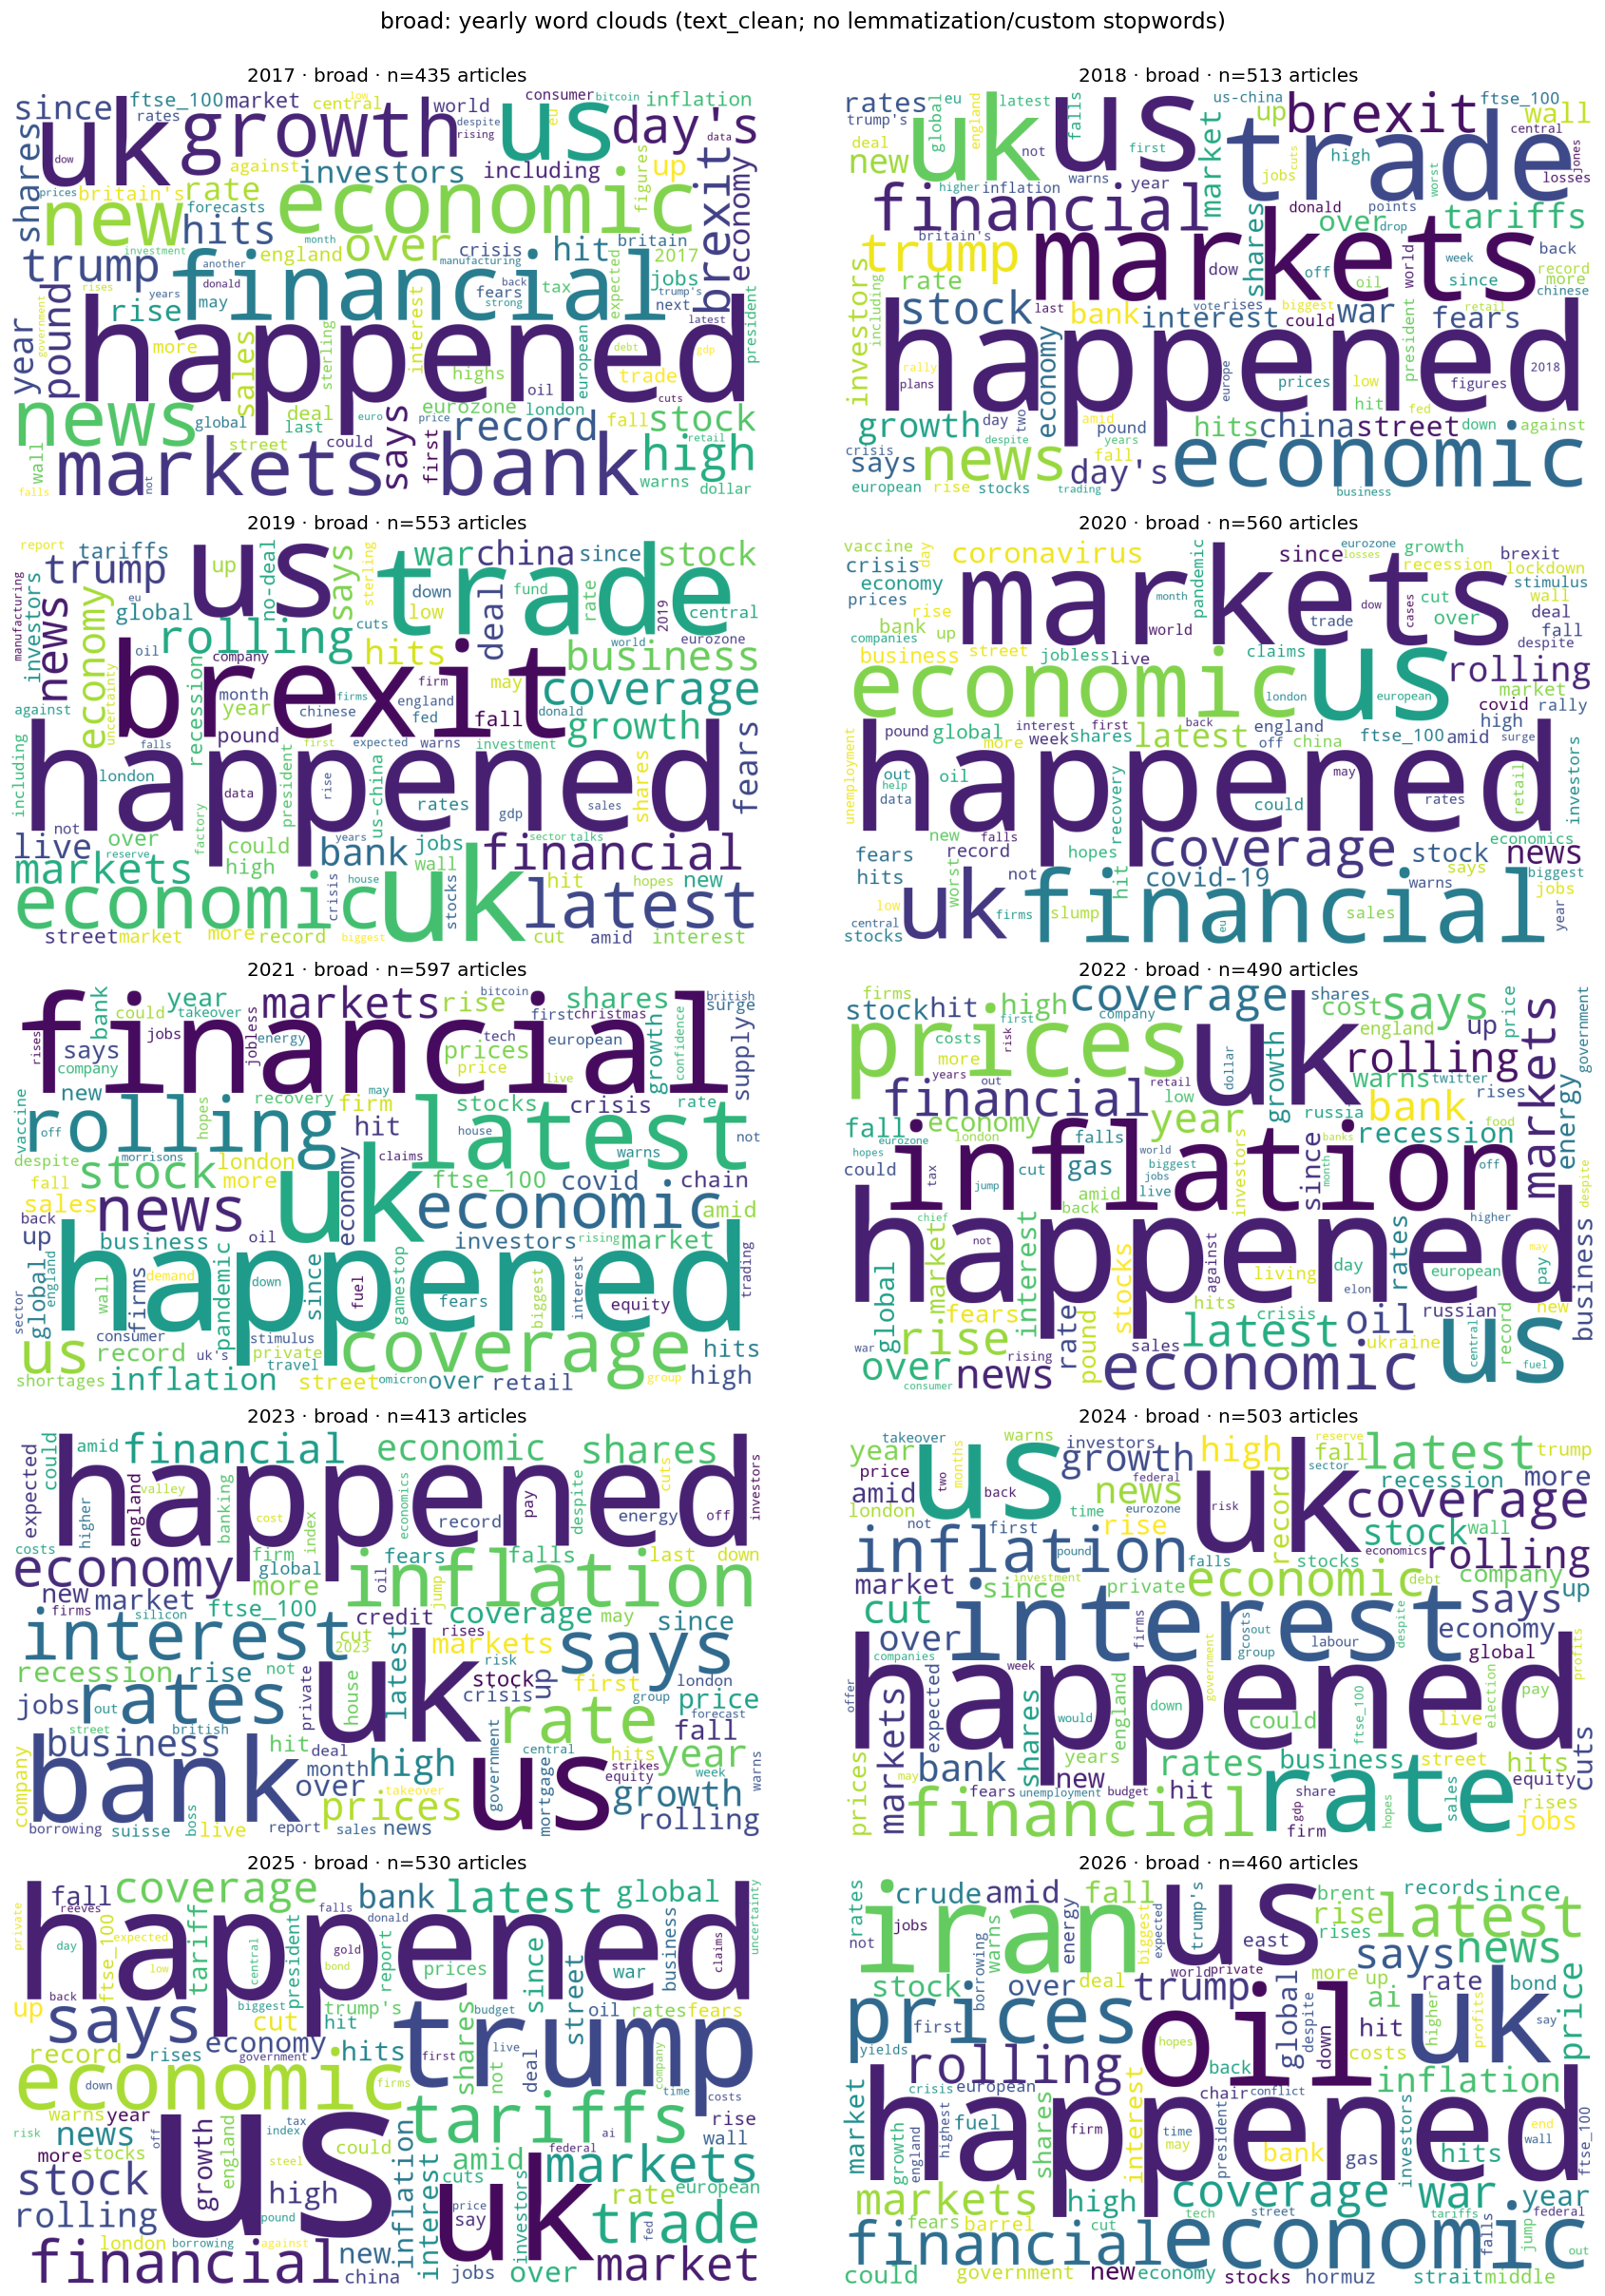

**strict · all years**

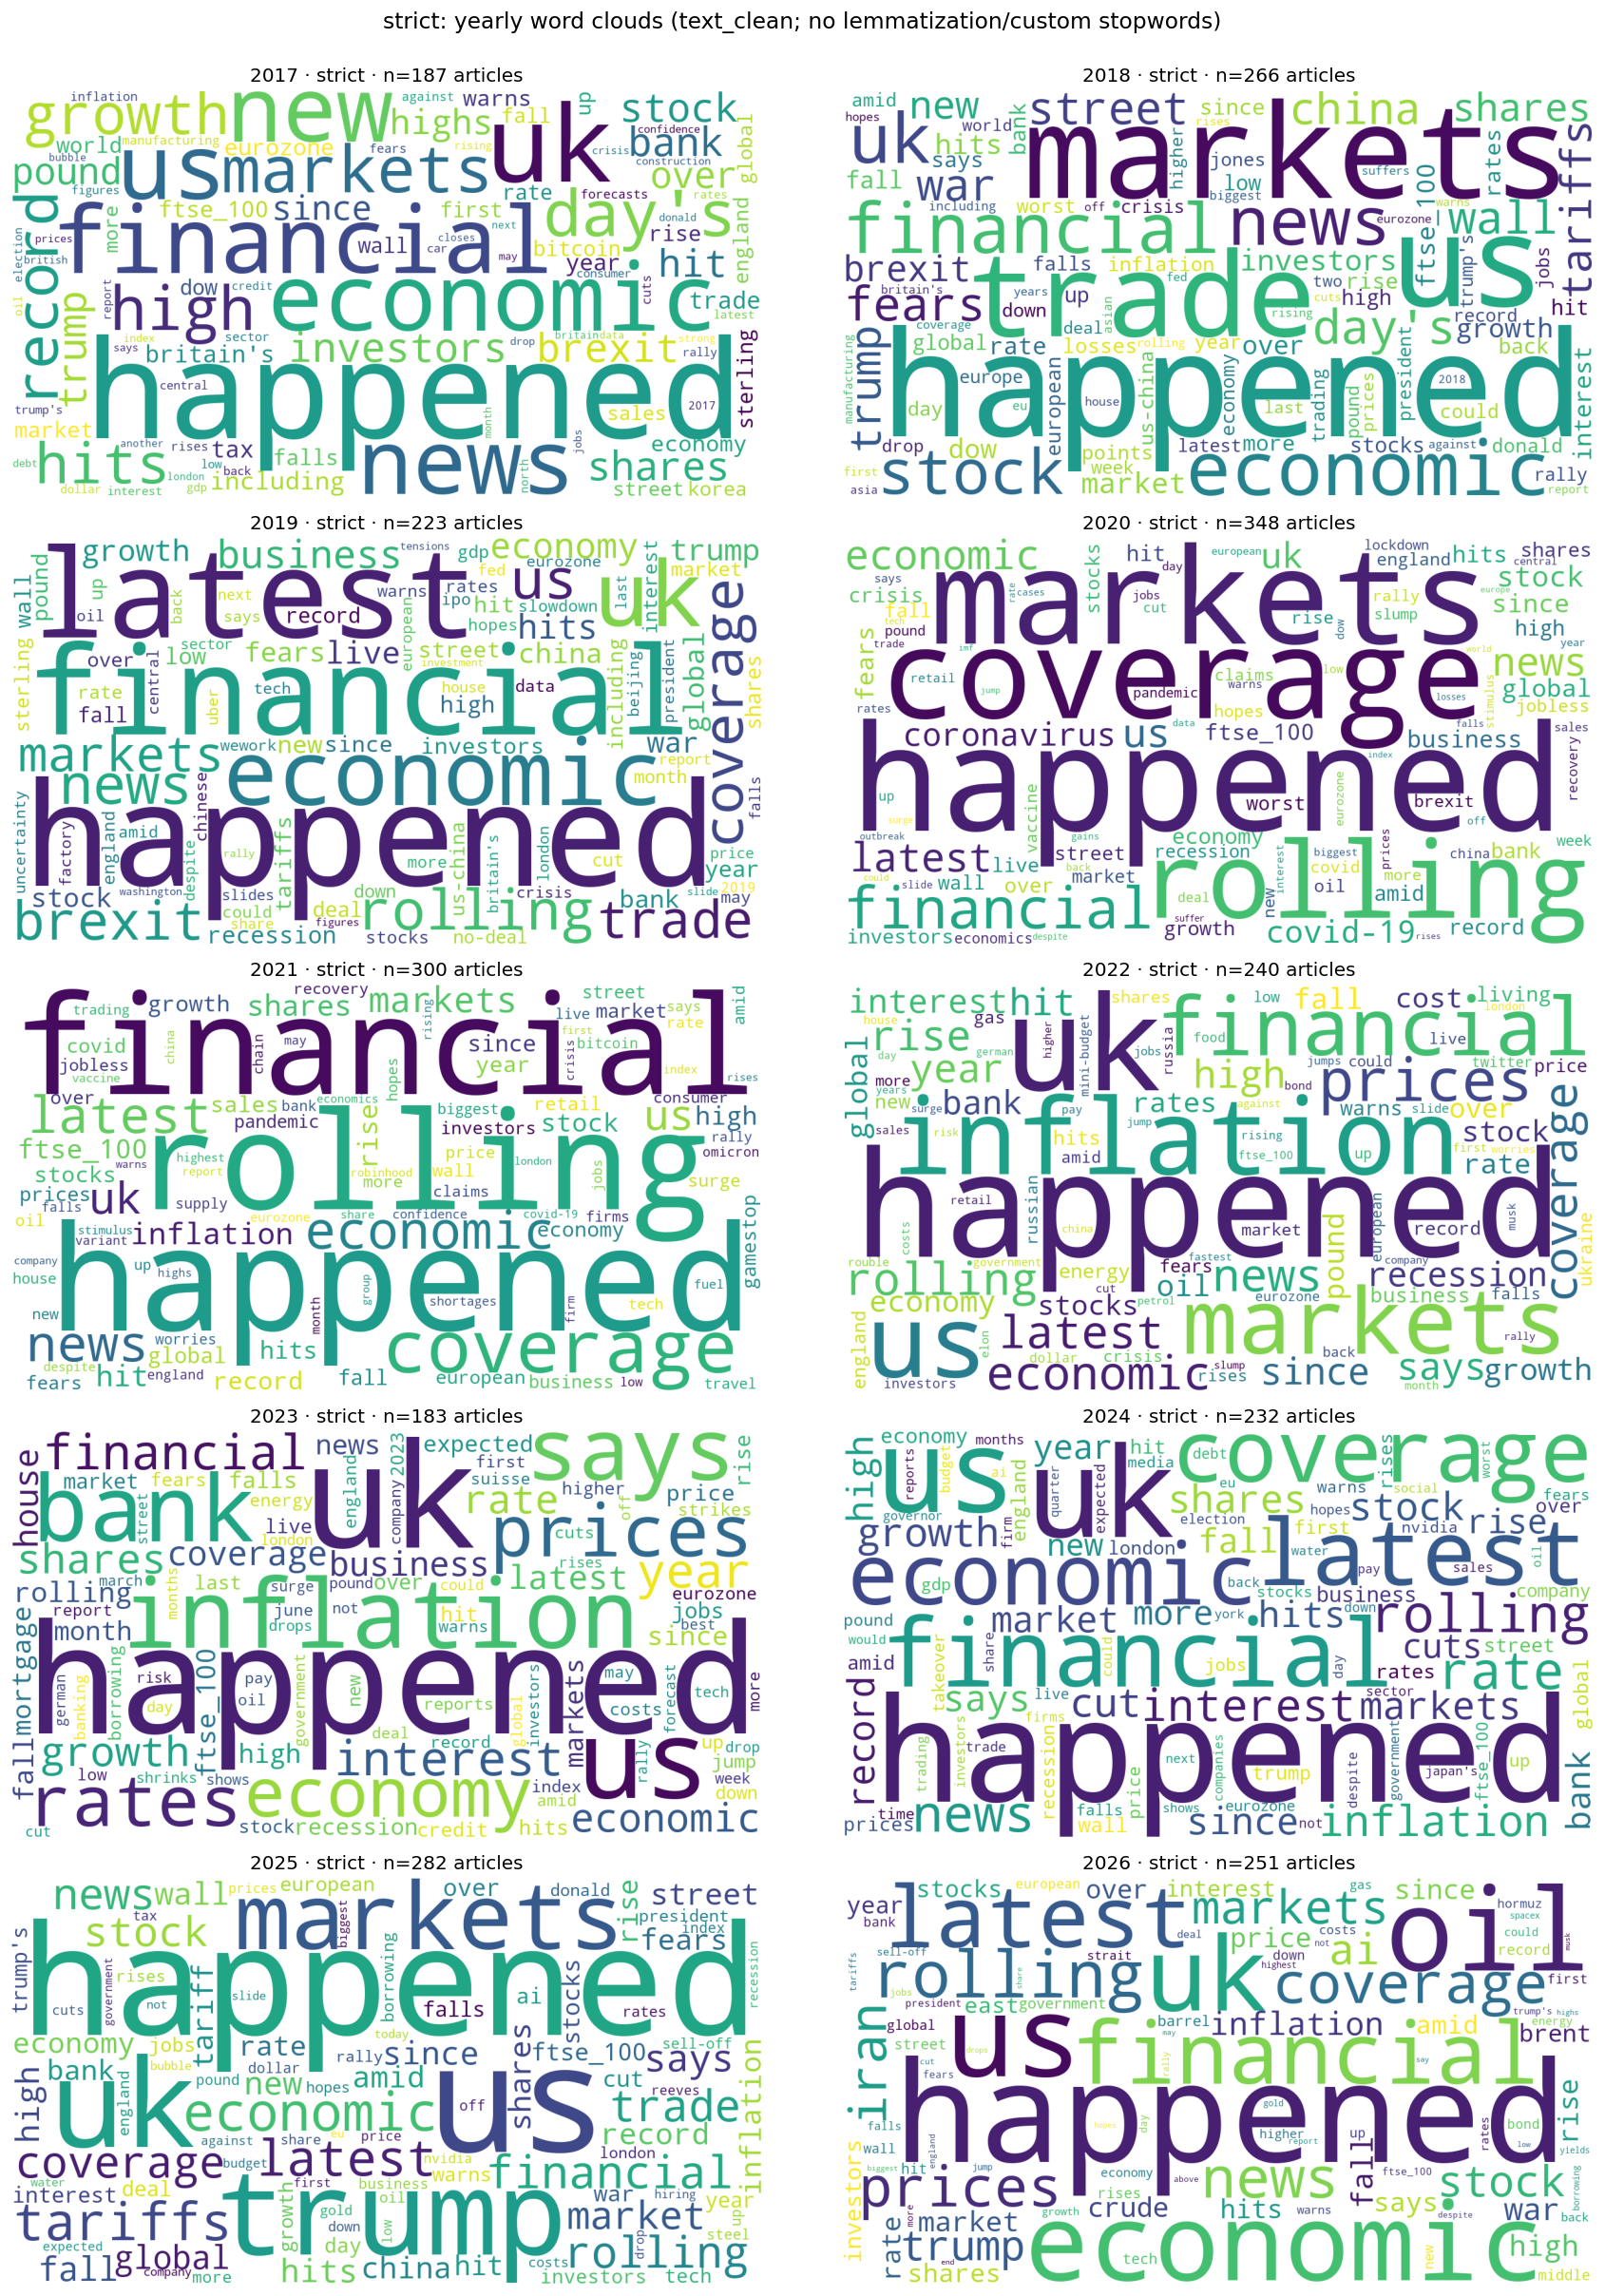

In [7]:
yearly=pd.read_csv(RESULTS/"yearly_top_word_frequencies.csv")
display(yearly.loc[yearly.query_strategy.eq(STRATEGY)].groupby("year").head(5))
for label in ["broad","strict"]:
    display(Markdown(f"**{label} · all years**"))
    display(Image(filename=str(BASE/f"figures/guardian_text_preprocessing/wordcloud_{label}_all_years.png"),width=1100))
DISPLAY_YEARS=[]  # 예: [2017,2020,2026]. 데이터/개별 그림은 모든 연도로 이미 저장됨.
for year in DISPLAY_YEARS:
    for label in ["broad","strict"]:
        display(Image(filename=str(BASE/f"figures/guardian_text_preprocessing/wordcloud_{label}_{year}.png"),width=1000))

## 7. 검증과 재실행
원본 열·전략 플래그·ID·원본 Parquet 해시를 비교하고 주간 토큰 집계도 재계산했다.
필요할 때만 전처리를 다시 실행한다. 실행해도 모델 점수나 외부 자료 결합을 수행하지 않는다.

In [8]:
print((RESULTS/"validation_summary.json").read_text(encoding="utf-8"))
RERUN_PREPROCESS=False
if RERUN_PREPROCESS:
    pipeline["main"]()
display(Markdown(f"진단 보고서: `{BASE / 'GUARDIAN_TEXT_PREPROCESSING_REVIEW.md'}`"))

{
  "status": "passed",
  "raw_columns_preserved_exactly": [
    "guardian_id",
    "published_at_original",
    "published_at_utc",
    "published_at_et",
    "date_et",
    "web_title",
    "headline",
    "description",
    "section_id",
    "section_name",
    "tags",
    "web_url",
    "content_type",
    "production_office",
    "api_record_json",
    "first_retrieved_at",
    "last_retrieved_at",
    "in_broad_business_control",
    "in_anchors_stock_market_tag",
    "query_strategy_membership",
    "year"
  ],
  "article_ids_verified": 5265,
  "one_physical_record_per_article": true,
  "weekly_article_token_and_unique_vocabulary_verified": true,
  "frequency_totals_verified": true,
  "raw_file_hashes_unchanged": true,
  "no_custom_stopwords_or_lemmatization": true,
  "no_sentiment_WSI_FGI_columns": true,
  "network_requests": 0
}


진단 보고서: `C:\Users\rhffl\data_mining\midterm paper\GUARDIAN_TEXT_PREPROCESSING_REVIEW.md`